# From a continuous potential to a tight-binding model - the `WannierHamiltonianBuilder` class

Maximally localized Wannier functions (MLWFs) can be used to compute the optimal tight-binding parameters of a given lattice and band group (see [[Ibañez-Azpiroz2013]](https://arxiv.org/abs/1211.6893) for the optical honeycomb lattice).

The `WannierHamiltonianBuilder` class of the `bloch_schrodinger.wannier_tb` module automates this procedure, it take as input:

+ the potential and its unit cell, as a `Potential` object (with any number of parameter dimensions),
+ the kinetic coefficient $\alpha = \hbar^2/2m$,
+ the tight-binding geometry used to describe it, as a `Lattice` object of the [`tightbinding`](https://github.com/GuillotMartin/tightbinding) package,

and returns a `tightbinding.Hamiltonianbuilder` in which every on-site energy and hopping amplitude is already computed, as a function of the parameters of the potential.

This tutorial builds on [Wannier.ipynb](Wannier.ipynb), for the Wannier functions, and on [tightbinding.ipynb](tightbinding.ipynb), for the `tightbinding` package, which must be installed separately:

```
pip install git+https://github.com/GuillotMartin/tightbinding
```

## How it works

**Wannier functions.** For a group of $N$ bands, the `Wannier` class finds unitary matrices $U^{\mathbf{k}}_{mn}$ that combine the Bloch eigenvectors $\ket{\psi_{m\mathbf{k}}}$ into maximally localized functions,

$$\ket{\tilde{\psi}_{n\mathbf{k}}} = \sum_m U^{\mathbf{k}}_{mn} \ket{\psi_{m\mathbf{k}}}, \qquad \ket{w_{n\mathbf{R}}} = \frac{1}{N_k}\sum_{\mathbf{k}} e^{i\mathbf{k}\cdot\mathbf{R}} \ket{\tilde{\psi}_{n\mathbf{k}}},$$

where the sum runs over the $N_k$ points of a Monkhorst-Pack mesh of the Brillouin zone.

**Hopping amplitudes.** Since $\hat{H}\ket{\psi_{m\mathbf{k}}} = E_{m\mathbf{k}}\ket{\psi_{m\mathbf{k}}}$, the matrix elements of the Hamiltonian between Wannier functions follow from the Bloch energies alone:

$$t_{ij}(\mathbf{R}) = \braket{w_{i\mathbf{0}}|\hat{H}|w_{j\mathbf{R}}} = \frac{1}{N_k}\sum_{\mathbf{k}} e^{i\mathbf{k}\cdot\mathbf{R}}\, H^{(W)}_{ij}(\mathbf{k}), \qquad H^{(W)}(\mathbf{k}) = U^{\mathbf{k}\dagger}\, \mathrm{diag}(E_{m\mathbf{k}})\, U^{\mathbf{k}}.$$

This is the *Wannier interpolation* of [[Marzari2012]](https://journals.aps.org/rmp/abstract/10.1103/RevModPhys.84.1419) (sec. VI).

**Tight-binding Hamiltonian.** The `tightbinding` package builds $H_{ij}(\mathbf{k}) = \sum_{\mathbf{R}} t_{ij}(\mathbf{R})\, e^{-i\mathbf{k}\cdot(\mathbf{R} + \mathbf{r}_j - \mathbf{r}_i)}$, which matches the $\mathbf{k}$ convention above.
**The pipeline.** The constructor of `WannierHamiltonianBuilder` runs five steps:

1. The MLWFs are computed with `Wannier`, one per orbital of the unit cell, starting from gaussians centered on the sites.
2. Each Wannier function is matched with the site it sits on.
3. The $t_{ij}(\mathbf{R})$ are computed for every translation resolved by the mesh, $|R_l| \leq (n_l - 1)/2$ unit cells along each lattice vector.
4. The couplings to keep are selected, by shells of neighbors (`neighbors`), maximal bond length (`cutoff`) or relative magnitude (`threshold`). Each bond is kept once, the builder adding its hermitian conjugate.
5. They are registered as `Energy` and `Hopping` terms, whose strengths are arrays over the parameter space of the potential.

**Requirements and limitations.**

+ The band group must be isolated from the other bands (there is no disentanglement procedure).
+ Each site carries a single, s-like orbital, described by a single Wannier function.
+ The `Lattice` must have the unit vectors of the `Potential`, and its sites must be given in the cartesian frame of the potential, close to the potential minima.

## Example: The strained honeycomb lattice

We consider an optical honeycomb lattice made by three blue-detuned beams at 120° from one another, whose interference creates a honeycomb lattice of intensity minima. Reducing the intensity of the first beam, by a fraction we call the `imbalance`, weakens one of the three nearest-neighbor bonds and progressively turns the honeycomb lattice into decoupled zig-zag chains.

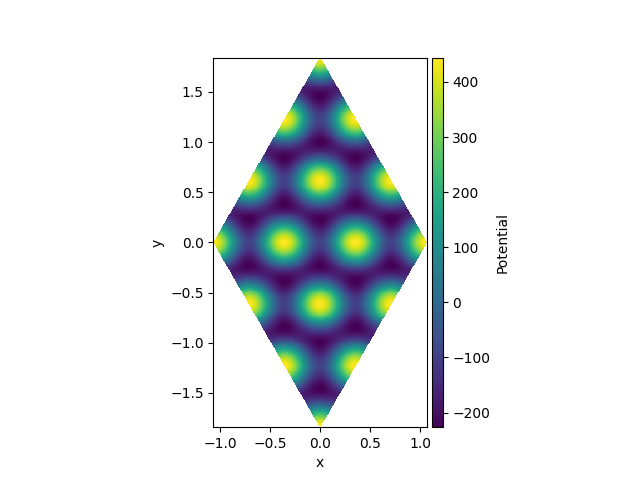

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from bloch_schrodinger.potential import Potential, create_parameter

# Units: µm and hbar = m = 1
lamb = 1.064
kl = 2 * np.pi / lamb
m = 1
hbar = 1
E_r = hbar**2 * kl**2 / 2 / m

# Lasers wavevectors and their differences
k1 = kl * np.array([1, 0])
k2 = kl * np.array([-1 / 2, -(3**0.5) / 2])
k3 = kl * np.array([-1 / 2, 3**0.5 / 2])
b1, b2, b3 = k2 - k1, k3 - k2, k3 - k1


# Lattice geometry
a1 = 2 / 3 * lamb * np.array([1 / 2, -(3**0.5) / 2])
a2 = 2 / 3 * lamb * np.array([1 / 2, 3**0.5 / 2])
a = 2 * 3**0.5 / 9 * lamb  # nearest-neighbor distance

K = np.array([4 * np.pi / 3**1.5 / a, 0]) #corner of the Brillouin zone

# Single-beam intensities, the first one modified by the imbalance
s0 = 10
imbalance = create_parameter("imbalance", np.linspace(0, 0.8, 5))
V1 = s0 * E_r * (1 - imbalance)
V2 = s0 * E_r
V3 = s0 * E_r

honeycomb = Potential(unitvecs=[a1, a2], resolution=(64, 64), v0=0)
dirs = [b[0] * (honeycomb.x - a1[0]) + b[1] * honeycomb.y for b in (b1, b2, b3)]
honeycomb.add((V1 * V2) ** 0.5 * np.cos(dirs[0]))
honeycomb.add((V2 * V3) ** 0.5 * np.cos(dirs[1]))
honeycomb.add((V3 * V1) ** 0.5 * np.cos(dirs[2]))

%matplotlib widget
fig, ax = honeycomb.tile([[-1, 2], [-1, 2]]).plot()
ax.set_aspect("equal")
plt.show()

## The tight-binding geometry

This potential can be described by a honeycomb lattices with sites sitting at $[0 ,\pm a/2]$, the thus build a Lattice object with the tightbinding package reproducing a single unit cell.

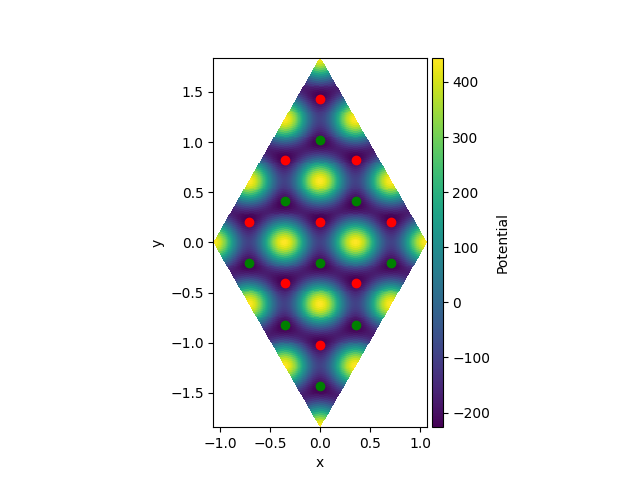

In [4]:
from tightbinding.geometry import Lattice, Orbital, Site, Unitcell

s_orbital = Orbital("s")
A_site = Site("A", [0, a / 2], s_orbital)
B_site = Site("B", [0, -a / 2], s_orbital)

honey_uc = Unitcell("honeycomb", np.array([a1, a2]))
honey_uc.add_site([A_site, B_site])

honeycomb_lattice = Lattice("honeycomb", honey_uc, (True, True))
honeycomb_lattice.add_unitcell((0, 0), update=True)

# The sites over the potential, in a few unit cells
fig, ax = honeycomb.tile([[-1, 2], [-1, 2]]).plot()
for i in range(-1, 2):
    for j in range(-1, 2):
        R = i * a1 + j * a2
        ax.plot(*(R + A_site.position), "o", color="red")
        ax.plot(*(R + B_site.position), "o", color="green")
ax.set_aspect("equal")
plt.show()

## Extracting the tight-binding model

Once the `Potential` and `Lattice` object are set, they can be passed to the `WannierHamiltonianBuilder` directly, who will handle everything else. A few additional parameters just need to be passed:

+ `k_resolution` is the k-space mesh used to compute the Wannier functions . It sets the range of the hoppings that can be resolved. See the [Wannier tutorial](docs/Wannier.ipynb) for more informations about this.
+ `neighbors`, `cutoff` and `threshold` select the couplings registered on the builder: the first `neighbors` shells of bond lengths of the lattice, the bonds shorter than `cutoff`, the hoppings stronger than `threshold` times the strongest one. All the criteria given apply together, but the threshold is off when a distance criterion is given, unless it is set explicitly. With no criterion at all, as here, it defaults to $10^{-3}$.
+ the remaining keyword arguments go to `Wannier.solve`.

In [5]:
from bloch_schrodinger.wannier_tb import WannierHamiltonianBuilder

H = WannierHamiltonianBuilder(
    potential=honeycomb,
    alpha=hbar**2 / 2 / m,
    lattice=honeycomb_lattice,
    neighbors=2, # We build a tight-binding description taking into account nearest and next-nearest neighbors.
    k_resolution=21,
    blockwargs={"E_lim": 200 * E_r},  # plane wave cut-off
    tol=1e-10,
    max_iter=500,
    parallel=True,
    seed=0,
)
print(H)

Computing the Bloch functions...


Diagonalizing (241 plane waves):   0%|          | 0/2205 [00:00<?, ?matrix/s]

Computing Wannier functions:   0%|          | 0/5 [00:00<?, ?set/s]

Minimization: 231 iterations on average, spread between 7.742e-06 and 0.0002745


Computing Wannier centers:   0%|          | 0/5 [00:00<?, ?set/s]

WannierHamiltonianBuilder on lattice 'honeycomb': orbitals ['A_s', 'B_s'], bands 0-1, k-mesh 21x21, parameters {'imbalance': 5}
11 terms (neighbors = 2 (<= 0.7093), cutoff = None, threshold = off):
  name                     orbitals         displacement   shell   distance  max |value|
  E_A_s                    A_s -> A_s       (0, 0)             0          0        154.5
  t_A_s_A_s_0_1            A_s -> A_s       (0, 1)             2     0.7093       0.1319
  t_A_s_A_s_1_0            A_s -> A_s       (1, 0)             2     0.7093       0.1319
  t_A_s_A_s_1_1            A_s -> A_s       (1, 1)             2     0.7093         1.46
  t_A_s_B_s_m1_0           A_s -> B_s       (-1, 0)            1     0.4095         6.93
  t_A_s_B_s_0_0            A_s -> B_s       (0, 0)             1     0.4095        2.406
  t_A_s_B_s_0_1            A_s -> B_s       (0, 1)             1     0.4095         6.93
  E_B_s                    B_s -> B_s       (0, 0)             0          0        154.5
 

Printing the builder lists the registered terms. Each one is named after its orbitals and displacement, `E_<orbital>` for an on-site energy and `t_<orbital 1>_<orbital 2>_<R1>_<R2>` for a hopping from orbital 1 in the home cell to orbital 2 in the cell $R_1 \mathbf{a}_1 + R_2 \mathbf{a}_2$ (a minus sign is written `m`). These names are the parameters the `Energy` and `Hopping` expressions refer to.

The values are gathered in a `tb_parameters` dataset, each variable corresponding to a coupling term.

In [6]:
H.tb_parameters

<xarray.Dataset> Size: 480B
Dimensions:         (imbalance: 5)
Coordinates:
  * imbalance       (imbalance) float64 40B 0.0 0.2 0.4 0.6 0.8
Data variables:
    E_A_s           (imbalance) float64 40B -154.5 -141.2 -128.7 -117.1 -106.4
    t_A_s_A_s_0_1   (imbalance) float64 40B 0.1319 0.1039 0.06916 0.036 0.01151
    t_A_s_A_s_1_0   (imbalance) float64 40B 0.1319 0.1039 0.06916 0.036 0.01151
    t_A_s_A_s_1_1   (imbalance) float64 40B 0.1319 0.2666 0.5077 0.9007 1.46
    t_A_s_B_s_m1_0  (imbalance) float64 40B -2.406 -3.28 -4.36 -5.613 -6.93
    t_A_s_B_s_0_0   (imbalance) float64 40B -2.406 -1.438 ... -0.3443 -0.1168
    t_A_s_B_s_0_1   (imbalance) float64 40B -2.406 -3.28 -4.36 -5.613 -6.93
    E_B_s           (imbalance) float64 40B -154.5 -141.2 -128.7 -117.1 -106.4
    t_B_s_B_s_0_1   (imbalance) float64 40B 0.1319 0.1038 0.06916 0.036 0.01151
    t_B_s_B_s_1_0   (imbalance) float64 40B 0.1319 0.1038 0.06916 0.036 0.01151
    t_B_s_B_s_1_1   (imbalance) float64 40B 0.1319 0.2666 0.5077 0.9007 1.46

The centers of the Wannier functions are kept as well. These centers are not exactly where the tight-binding description places them, this is harmless for the computation of the band structure, but it can affect the geometry of the computed tight-binding eigenvectors.

In [7]:
H.centers.sel(axis="y")/a

<xarray.DataArray (imbalance: 5, orbital: 2)> Size: 80B
array([[ 0.5       , -0.5       ],
       [ 0.53868381, -0.53868381],
       [ 0.57869712, -0.57869712],
       [ 0.62077802, -0.62077802],
       [ 0.6677942 , -0.6677942 ]])
Coordinates:
  * imbalance  (imbalance) float64 40B 0.0 0.2 0.4 0.6 0.8
  * orbital    (orbital) <U3 24B 'A_s' 'B_s'
    axis       <U1 4B 'y'

## Band structure

The object is now used as any `Hamiltonianbuilder`. To compute the bands along a path of the Brillouin zone, we add a path coordinate `s` and register $k_x$ and $k_y$ as coordinates along it. Since every amplitude is stored, this requires no new computation.

In [8]:

# Let's create a grid going through the high-symmetry points
M_to_Kp = np.linspace(b1[0], -K[0], 5, endpoint=False)
Kp_to_K = np.linspace(-K[0], K[0], 30, endpoint=False)
K_to_M = np.linspace(K[0], -b1[0], 5)
kxpoints = np.concatenate([M_to_Kp, Kp_to_K, K_to_M])

H.add_parameters({"kx": kxpoints, "ky": 0})

H.build()
bands_tb, vectors_tb = H.eigh()

We compare with the plane wave solver, on the same path:

Diagonalizing (241 plane waves):   0%|          | 0/200 [00:00<?, ?matrix/s]

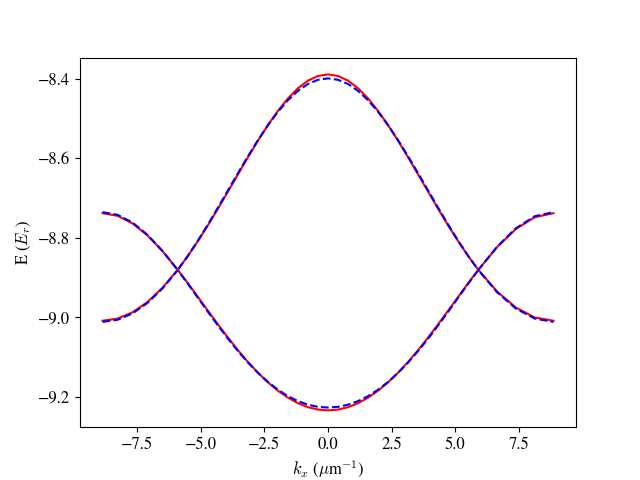

In [9]:
from bloch_schrodinger.plotting import plot_cuts
from bloch_schrodinger.pwsolver import PWSolver

pw = PWSolver(honeycomb, alpha=hbar**2 / 2 / m, E_lim=200 * E_r)
pw.create_reciprocal_grid([kxpoints, 0])
bands_pw, _ = pw.solve(2, parallel=True)

# kx and ky are attached to the tight-binding bands as coordinates, they are dropped before comparing
bands_tb = bands_tb.real.reset_coords(drop=True)
bands_pw = bands_pw.reset_coords(drop=True)

# Interleave the two band structures, to style them separately
bands_pw.coords["band"] = 2 * np.arange(2)
bands_tb.coords["band"] = 2 * np.arange(2) + 1
eigva = xr.concat([bands_pw, bands_tb], dim="band").sortby("band") / E_r

template_tb = {"color": "blue", "linestyle": "dashed"}
template_pw = {"color": "red"}

fig, ax = plot_cuts(eigva, "kx", linekws=[template_pw, template_tb])
ax.set_xlabel(r"$k_x$ ($\mu$m$^{-1}$)")
ax.set_ylabel("E ($E_r$)")
plt.show()

The two band structures are close from one another, but with a marked degradation for large imbalances. This is expected, as the coupling betweem sites in the same chain increases, the accuracy of the tight-binding model decreases. This could be remedied by taking into account more shells, for example.

## Using the tight-binding parameters

Because the amplitudes of every resolved coupling term is stored in the `hoppings` array, with dimensions `(<parameters>, orb1, orb2, R1, R2)`, it is easy to follow a given bond as a function of the parameters. Here, the three nearest-neighbor hoppings $A \to B$:

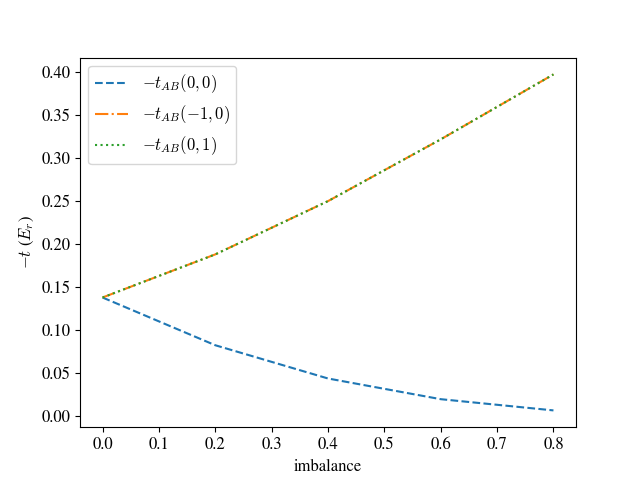

In [10]:
links = [(0, 0), (-1, 0), (0, 1)]
nearest = xr.concat(
    [H.hoppings.sel(orb1="A_s", orb2="B_s", R1=R1, R2=R2, drop=True) for R1, R2 in links],
    dim=xr.DataArray([str(link) for link in links], dims="link"),
)

fig, ax = plot_cuts(-nearest / E_r, "imbalance", groupby=["link"], linekws=[{"linestyle": ls} for ls in ["--", "-.", ":"]])
ax.legend([f"$-t_{{AB}}{link}$" for link in links])
ax.set_ylabel("$-t$ ($E_r$)")
plt.show()

The bond $(0,0)$ is weakened by the imbalance, while the two others are reinforced: the lattice turns into zig-zag chains running along $x$. The ratio between the hopping across the chains and the hopping along them measures how decoupled they are:

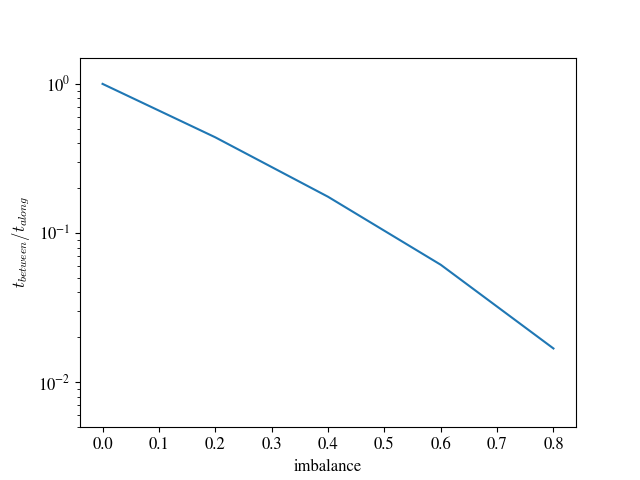

In [15]:
t_between = H.hoppings.sel(orb1="A_s", orb2="B_s", R1=0, R2=0, drop=True)
t_along = H.hoppings.sel(orb1="A_s", orb2="B_s", R1=0, R2=1, drop=True)

# Explicit y bounds, otherwise plot_cuts rescales the axis linearly
fig, ax = plot_cuts(t_between / t_along, "imbalance", groupby=[], ymin = 5e-3, ymax = 1.5)
ax.set_yscale("log")
ax.set_ylabel("$t_{between} / t_{along}$")
plt.show()

## Choosing which couplings to keep

The selection arguments only decide which of the computed amplitudes are registered on the builder. Two kinds of criteria are available:

+ geometric ones: `neighbors` keeps whole shells of neighbors, and `cutoff` the bonds shorter than a given length. The shells are those of the site positions of the lattice, listed in `shell_distances`:

In [16]:
print("Shell distances, in units of a:", np.round(H.shell_distances[:6] / a, 4))

Shell distances, in units of a: [1.     1.7321 2.     2.6458 3.     3.4641]


+ a magnitude one: `threshold` keeps the hoppings whose largest magnitude over the parameter space is at least `threshold` times that of the strongest one.

The `on_lattice` method returns a new builder sharing the computed amplitudes, so it is possible to change the hopping considered without new Wannier computation.

## Other geometries

The `Hopping` terms are defined per unit cell displacement, so the same parameters describe any lattice built from the same unit cell, like a ribbon for example. `on_lattice` builds them without recomputing anything. Here, a zig-zag ribbon, periodic along $\mathbf{a}_1$ and 16 unit cells wide along $\mathbf{a}_2$:

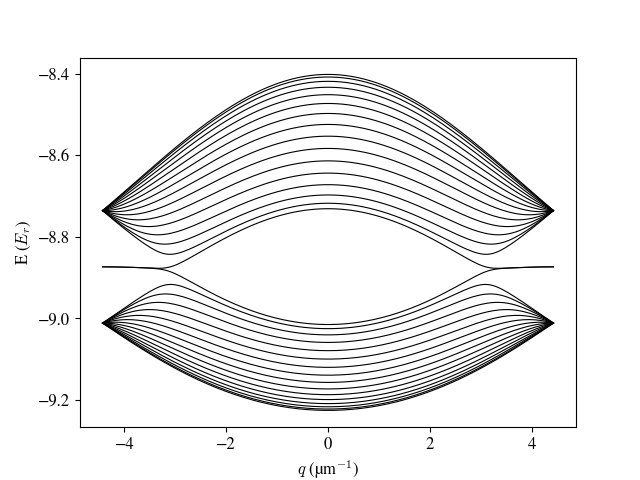

In [19]:
ribbon = Lattice("ribbon", honey_uc, (True, False))
ribbon.create_rectangle_lattice((1, 16))

# k along the periodic direction
u1 = a1 / np.linalg.norm(a1)
q = np.linspace(-np.pi, np.pi, 151) / np.linalg.norm(a1)

H_ribbon = H.on_lattice(lattice=ribbon, params={"q": q})
H_ribbon.add_multidimensional_coord("kx", q * u1[0], ("q",))
H_ribbon.add_multidimensional_coord("ky", q * u1[1], ("q",))
H_ribbon.build()
bands_ribbon, _ = H_ribbon.eigh()

fig, ax = plot_cuts(bands_ribbon.real.reset_coords(drop=True) / E_r, "q", linekws={"color": "k", "linewidth": 0.8})
ax.set_xlabel(r"$q$ (µm$^{-1}$)")
ax.set_ylabel("E ($E_r$)")
plt.show()